# Agentic vs classic pipeline: results notebook

Analyses the runs produced by `run_models.sh`. One folder per model, for example `runs/gemma-4-26b-a4b/`, containing `timing.csv`, `llm_calls.jsonl`, `trace.jsonl`,`comparison/{per_hour,per_node}.csv`, `comparison/summary.json` and optionally `logs/`.


| Priority | Section | Question |
|---|---|---|
| 1 | Workflow and prediction fidelity | Does agentic orchestration preserve the deterministic operations? |
| 2 | Traffic classification agreement | Do agents reproduce the expected verdicts (node, corridor, network)? |
| 3 | Failure and disagreement analysis | Why do the agents differ from the baseline? |
| 4 | Execution time | Is hourly operation feasible? |
| 5 | LLM resource consumption | Tokens, context, summarisation, turns, errors |
| 6 | Five-year cost | Local hardware vs API, break-even |

Every table is also written to `analysis_out/` as CSV.

In [1]:
import json, re, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import cohen_kappa_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ------------------------------ configuration ------------------------------ #
RUNS = {
  "Gemma (subagents) run 1": "runs/gemma-4-26b-a4b",
  "Gemma (subagents) run 2": "runs_2/gemma-4-26b-a4b",
  "Qwen (subagents) run 1":  "runs/qwen3.8-27b",
  "Qwen (subagents) run 2":  "runs_2/qwen3.8-27b",      
}

CLASSIC_DIR   = "runs/classic_ref/classic"  # hour_*.json written by classic_runner.py
CONTEXT_LIMIT = 24000                       # GOOSE_CONTEXT_LIMIT
MAX_TURNS     = 150                         # GOOSE_MAX_TURNS
STALL_S       = 300                         # a single LLM request slower than this counts as a stall
RUNAWAY_TOKENS = 20000                      # a single response longer than this counts as a runaway
FEASIBLE_S    = 3600                        # hourly operation: a session must finish within this
OUT = Path("analysis_out"); OUT.mkdir(exist_ok=True)

# ------------------------------ chart styling ------------------------------ #
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
COLORS = {"Gemma": "#2a78d6", "Qwen": "#eb6834", "Classic": "#8a8984"}   # fixed order: blue, orange, gray
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "regular",
    "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 80)

def show(df, title, name=None, index=True):
    display(Markdown(f"**{title}**"))
    display(df)
    if name:
        df.to_csv(OUT / f"{name}.csv", index=index)

## Load data

In [2]:
def read_jsonl(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    pass
    return pd.DataFrame(rows)

CALL_COLS = ["prompt_tokens", "completion_tokens", "latency_s", "ttft_s", "retries", "queue_wait_s",
             "n_messages", "cached_tokens", "status"]

def load_run(name, path):
    p = Path(path)
    if not (p / "timing.csv").exists():
        return None
    r = {"name": name, "path": p}
    r["timing"] = pd.read_csv(p / "timing.csv").drop_duplicates("hour", keep="last").reset_index(drop=True)
    calls = read_jsonl(p / "llm_calls.jsonl") if (p / "llm_calls.jsonl").exists() else pd.DataFrame()
    for c in CALL_COLS:
        if c not in calls:
            calls[c] = np.nan
    for c in ("finish_reason", "error", "usage_source", "hour"):
        if c not in calls:
            calls[c] = None
    if "summarize_hint" not in calls:
        calls["summarize_hint"] = False
    calls = calls[calls.hour.isin(r["timing"].hour)].copy()
    calls["summarize_hint"] = calls.summarize_hint.fillna(False).astype(bool)
    r["calls"] = calls
    r["trace"] = read_jsonl(p / "trace.jsonl") if (p / "trace.jsonl").exists() else pd.DataFrame()
    cmp_dir = p / "comparison"
    r["per_hour"] = pd.read_csv(cmp_dir / "per_hour.csv") if (cmp_dir / "per_hour.csv").exists() else None
    r["per_node"] = pd.read_csv(cmp_dir / "per_node.csv") if (cmp_dir / "per_node.csv").exists() else None
    sj = cmp_dir / "summary.json"
    r["summary"] = json.loads(sj.read_text()) if sj.exists() else {}
    if r["per_hour"] is not None:
        r["ph_last"] = r["per_hour"][r["per_hour"].session_is_last_for_hour.astype(bool)].copy()
    return r

def load_classic(directory):
    recs = {}
    for p in sorted(Path(directory).glob("hour_*.json")):
        j = json.loads(p.read_text())
        if j.get("hour") and not j.get("fatal_error"):
            recs[pd.Timestamp(j["hour"]).isoformat()] = j
    return recs

R = {n: r for n, p in RUNS.items() if (r := load_run(n, p))}
CLASSIC = load_classic(CLASSIC_DIR) if Path(CLASSIC_DIR).exists() else {}
assert R, "no run folder found: check RUNS at the top"
rows = [{"run": n, "sessions (timing.csv)": len(r["timing"]), "LLM requests": len(r["calls"]),
         "trace records": len(r["trace"]), "per_hour rows": None if r["per_hour"] is None else len(r["per_hour"]),
         "per_node rows": None if r["per_node"] is None else len(r["per_node"])} for n, r in R.items()]
show(pd.DataFrame(rows).set_index("run"), f"Loaded runs (classic reference: {len(CLASSIC)} hours)")

**Loaded runs (classic reference: 169 hours)**

,sessions (timing.csv),LLM requests,trace records,per_hour rows,per_node rows
run,,,,,
Gemma (subagents) run 1,169,21182,22430,169,2028
Gemma (subagents) run 2,169,20981,22802,170,2028
Qwen (subagents) run 1,169,15472,20540,169,2028
Qwen (subagents) run 2,169,16601,22310,169,2028


## 1. Workflow and prediction fidelity (essential)

Reference = the classic run (same models, same data). Call-level counts use every agent session;
node-hour comparisons use the last session of each hour.

In [3]:
def num(s):
    return pd.to_numeric(s, errors="coerce")

def share(a, b):
    return None if not b else round(a / b, 4)

def fidelity(r):
    ph, last, pn = r["per_hour"], r["ph_last"], r["per_node"]
    t = r["timing"]
    d = {}
    exit_ok = t.goose_exit.astype(str).eq("0").sum()
    complete = (last.log_run_summary_ok.astype(bool) & last.log_final_ditto_ok.astype(bool)).sum()
    d[("Sessions", "classic hours in the reference")] = len(CLASSIC) or None
    d[("Sessions", "agent sessions run")] = len(t)
    d[("Sessions", "goose exit code 0")] = f"{exit_ok} ({share(exit_ok, len(t))})"
    d[("Sessions", "completed (run summary + final Ditto logged)")] = f"{complete} ({share(complete, len(last))})"
    d[("Sessions", "repeated sessions for an hour")] = len(ph) - len(last)
    bst = last.build_summary_table_ok
    d[("Sessions", f"build_summary_table succeeded for both corridors")] = f"{(bst >= 2).sum()} of {len(last)}"
    d[("Sessions", "build_summary_table succeeded for no corridor")] = f"{(bst == 0).sum()} of {len(last)}"
    # coverage
    cl = int(last.classic_logged.sum()); ag = int(last.agent_logged.sum())
    miss = int(last.missing_nodes.fillna("").map(lambda s: len(s.split())).sum())
    extra = int(last.extra_nodes.fillna("").map(lambda s: len(s.split())).sum())
    d[("Prediction coverage", "node-hours classic predicted")] = cl
    d[("Prediction coverage", "node-hours agent predicted")] = ag
    d[("Prediction coverage", "mean coverage vs classic")] = round(last.coverage_vs_classic.mean(), 4)
    d[("Prediction coverage", "missing node-hours")] = f"{miss} ({share(miss, cl)})"
    d[("Prediction coverage", "extra node-hours")] = extra
    d[("Prediction coverage", "sessions with full coverage")] = f"{(last.coverage_vs_classic == 1).sum()} of {len(last)}"
    # input correctness
    calls = int(ph.baseline_predict_calls.sum()); bad = int(ph.payload_bad_calls.sum())
    d[("Input correctness", "baseline_predict calls")] = calls
    d[("Input correctness", "calls with a wrong payload")] = f"{bad} ({share(bad, calls)})"
    d[("Input correctness", "get_flows calls for the wrong hour")] = int(ph.get_flows_wrong_hour.sum())
    d[("Input correctness", "calls to nodes that should not be touched")] = int(ph.unexpected_node_calls.sum())
    # prediction agreement
    both = pn[num(pn.abs_diff).notna()]
    d[("Prediction agreement", "node-hours compared")] = len(both)
    d[("Prediction agreement", "exact match (|diff| <= tol)")] = share(int(both.pred_match.astype(bool).sum()), len(both))
    d[("Prediction agreement", "mean abs diff (veh/h)")] = round(num(both.abs_diff).mean(), 4)
    d[("Prediction agreement", "max abs diff (veh/h)")] = round(num(both.abs_diff).max(), 4)
    wa = pn[num(pn.smape_agent).notna() & num(pn.smape_classic).notna()]
    d[("Forecast accuracy vs observed", "mean SMAPE classic")] = round(num(wa.smape_classic).mean(), 4)
    d[("Forecast accuracy vs observed", "mean SMAPE agent")] = round(num(wa.smape_agent).mean(), 4)
    d[("Forecast accuracy vs observed", "share of node-hours where agent is worse")] = share(
        int((num(wa.smape_agent) > num(wa.smape_classic) + 1e-9).sum()), len(wa))
    # evaluation correctness
    ev = last[last.evaluation_expected.astype(bool)]
    cd = int(ph.check_deviation_calls.sum()); cdb = int(ph.check_deviation_bad_args.sum())
    d[("Evaluation correctness", "sessions where an evaluation was expected")] = len(ev)
    d[("Evaluation correctness", "mean evaluation coverage vs classic")] = round(ev.eval_coverage_vs_classic.mean(), 4)
    d[("Evaluation correctness", "check_deviation calls")] = cd
    d[("Evaluation correctness", "check_deviation calls with wrong arguments")] = f"{cdb} ({share(cdb, cd)})"
    d[("Evaluation correctness", "overall verdict matches classic")] = share(int(last.overall_verdict_match.astype(bool).sum()), len(last))
    d[("Evaluation correctness", "run-summary counts match classic")] = share(int(last.summary_counts_match.astype(bool).sum()), len(last))
    return d

fid = pd.DataFrame({n: fidelity(r) for n, r in R.items() if r["per_hour"] is not None})
fid.index.names = ["Area", "Metric"]
show(fid, "Workflow and prediction fidelity", "1_fidelity")

**Workflow and prediction fidelity**

Gemma (subagents) run 1 Gemma (subagents) run 2 Qwen (subagents) run 1 Qwen (subagents) run 2
Area                          Metric                                                                                                                                        
Sessions                      classic hours in the reference                                       169                     169                    169                    169
                              agent sessions run                                                   169                     169                    169                    169
                              goose exit code 0                                              169 (1.0)               169 (1.0)              169 (1.0)              169 (1.0)
                              completed (run summary + final Ditto logged)                   169 (1.0)            167 (0.9882)           164 (0.9704)           164 (0.9704)
                              repeated sessions for an hour                                          0                       1                      0                      0
                              build_summary_table succeeded for both corridors               90 of 169               87 of 169             164 of 169             164 of 169
                              build_summary_table succeeded for no corridor                  32 of 169               43 of 169               5 of 169               4 of 169
Prediction coverage           node-hours classic predicted                                        2028                    2028                   2028                   2028
                              node-hours agent predicted                                          1936                    1938                   1754                   1880
                              mean coverage vs classic                                          0.9546                  0.9556                 0.8649                  0.927
                              missing node-hours                                           92 (0.0454)             90 (0.0444)           274 (0.1351)            148 (0.073)
                              extra node-hours                                                       0                       0                      0                      0
                              sessions with full coverage                                   117 of 169              117 of 169              96 of 169             126 of 169
Input correctness             baseline_predict calls                                              2101                    2103                   1891                   2007
                              calls with a wrong payload                                  162 (0.0771)            156 (0.0742)            16 (0.0085)             9 (0.0045)
                              get_flows calls for the wrong hour                                     0                       0                      2                      2
                              calls to nodes that should not be touched                              0                       0                      0                      0
Prediction agreement          node-hours compared                                                 1930                    1938                   1751                   1879
                              exact match (|diff| <= tol)                                        0.999                   0.999                    1.0                    1.0
                              mean abs diff (veh/h)                                             0.5682                  0.5659                    0.0                    0.0
                              max abs diff (veh/h)                                               596.7                   596.7                    0.0                    0.0
Forecast accuracy vs observed mean SMAPE classic                                                0.06

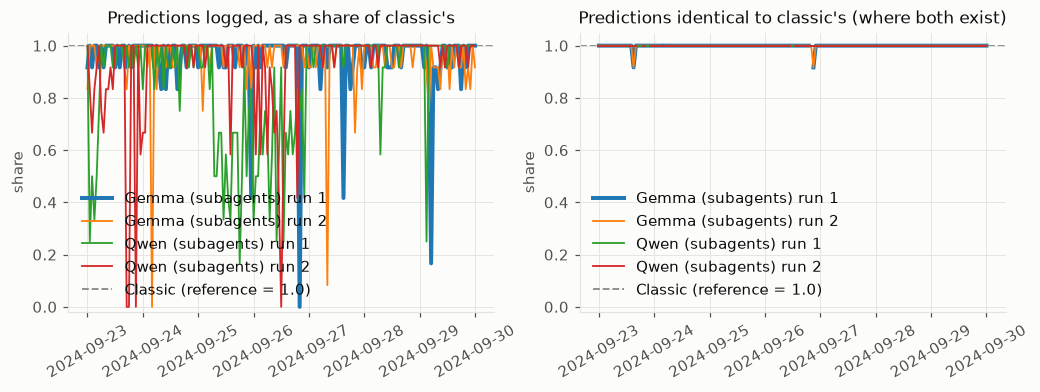

In [4]:
# coverage and agreement over time: one line per model, same axis
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharex=False)
for n, r in R.items():
    if r["per_hour"] is None:
        continue
    l = r["ph_last"].sort_values("hour")
    x = pd.to_datetime(l.hour)
    lw = 2.6 if n == list(R)[0] else 1.2          # first model thicker, so overlapping lines stay visible
    axes[0].plot(x, l.coverage_vs_classic, color=COLORS.get(n), label=n, lw=lw)
    pn = r["per_node"].copy(); pn["hour"] = pd.to_datetime(pn.hour)
    m = pn.groupby("hour").pred_match.apply(lambda s: s.dropna().astype(bool).mean())
    axes[1].plot(m.index, m.values, color=COLORS.get(n), label=n, lw=lw)

axes[0].set_title("Predictions logged, as a share of classic's"); axes[0].set_ylim(-0.02, 1.05)
axes[1].set_title("Predictions identical to classic's (where both exist)"); axes[1].set_ylim(-0.02, 1.05)
for a in axes:
    a.axhline(1.0, color=COLORS["Classic"], ls="--", lw=1.2, zorder=1, label="Classic (reference = 1.0)")
    a.set_ylabel("share"); a.legend(loc="lower left"); a.tick_params(axis="x", rotation=30)

## 2. Traffic classification agreement (essential)

Three levels, all compared with the classic verdict rules (a reference, not ground truth):

* **Detector (node):** per node and hour, `verdict_classic` vs `verdict_agent`.
* **Corridor:** one verdict per direction (`arrabida-freixo`, `freixo-arrabida`). Classic's value comes from the classic record;
  the agent's is derived with the same roll-up rule (`macro_drift` > `localized_event` > `within_baseline` > `pending`)
  from the node verdicts it reported, because the agent logs no corridor verdict of its own.
* **Network:** the overall verdict of the session (`log_run_summary.corridor_verdict` for the agent).

`not_reported` means the agent produced no verdict for that node or session.
Cohen's kappa is shown with and without trivial all-`pending` rows, and the class counts are shown
because kappa is unstable when almost every row is `within_baseline`.

In [5]:
NODE_LABELS = ["macro_drift", "localized_event", "within_baseline", "pending", "not_reported"]

def clean(v):
    return "not_reported" if v is None or (isinstance(v, float) and np.isnan(v)) or v == "" else str(v)

def rollup(vs):
    for v in ("macro_drift", "localized_event", "within_baseline"):
        if v in vs:
            return v
    return "pending"

def node_to_label():
    m = {}
    for rec in CLASSIC.values():
        for lab, ns in rec.get("nodes", {}).items():
            for n in ns:
                m[n["node"]] = lab
    return m

def levels(r):
    pn = r["per_node"]; pn = pn[pn.verdict_classic.notna()]
    node = pd.DataFrame({"classic": pn.verdict_classic.map(clean), "agent": pn.verdict_agent.map(clean)})
    corr = pd.DataFrame(columns=["classic", "agent"])
    if CLASSIC:
        nl = node_to_label()
        t = pn.assign(label=pn.node.map(nl)).dropna(subset=["label"])
        rows = []
        for (hour, lab), g in t.groupby(["hour", "label"]):
            cv = CLASSIC.get(pd.Timestamp(hour).isoformat(), {}).get("corridor_verdicts", {}).get(lab)
            if cv:
                rows.append({"classic": cv, "agent": rollup([clean(v) for v in g.verdict_agent])})
        corr = pd.DataFrame(rows, columns=["classic", "agent"])
    l = r["ph_last"]
    net = pd.DataFrame({"classic": l.classic_overall_verdict.map(clean), "agent": l.agent_overall_verdict.map(clean)})
    return {"Detector (node)": node, "Corridor": corr, "Network (overall)": net}

def confusion(df):
    labs = [x for x in NODE_LABELS if x in set(df.classic) | set(df.agent)]
    labs += sorted((set(df.classic) | set(df.agent)) - set(labs))
    cat = pd.CategoricalDtype(labs)
    return pd.crosstab(df.classic.astype(cat), df.agent.astype(cat), dropna=False), labs

def kappa(df, labs):
    if df.empty or df.classic.nunique() < 1:
        return np.nan
    try:
        return round(cohen_kappa_score(df.classic, df.agent, labels=labs), 4)
    except Exception:
        return np.nan

def agreement_rows(r):
    out = {}
    for level, df in levels(r).items():
        if df.empty:
            continue
        cm, labs = confusion(df)
        nontrivial = df[~((df.classic == "pending") & df.agent.isin(["pending", "not_reported"]))]
        out[(level, "rows compared")] = len(df)
        out[(level, "raw agreement")] = round((df.classic == df.agent).mean(), 4)
        out[(level, "Cohen's kappa")] = kappa(df, labs)
        out[(level, "rows excluding trivial pending")] = len(nontrivial)
        out[(level, "raw agreement excluding trivial pending")] = round((nontrivial.classic == nontrivial.agent).mean(), 4) if len(nontrivial) else None
        out[(level, "Cohen's kappa excluding trivial pending")] = kappa(nontrivial, labs)
        out[(level, "agent verdict missing (not_reported)")] = int((df.agent == "not_reported").sum())
        for c in ("macro_drift", "localized_event"):
            sup = int((df.classic == c).sum())
            tp = int(((df.classic == c) & (df.agent == c)).sum())
            pred = int((df.agent == c).sum())
            out[(level, f"{c}: classic count / recall / precision")] = f"{sup} / {share(tp, sup)} / {share(tp, pred)}"
    return out

agree = pd.DataFrame({n: agreement_rows(r) for n, r in R.items() if r["per_node"] is not None})
agree.index.names = ["Level", "Metric"]
show(agree, "Verdict agreement with classic", "2_agreement")

**Verdict agreement with classic**

Gemma (subagents) run 1 Gemma (subagents) run 2 Qwen (subagents) run 1 Qwen (subagents) run 2
Level             Metric                                                                                                                                           
Detector (node)   rows compared                                                          2028                    2028                   2028                   2028
                  raw agreement                                                         0.573                  0.5897                 0.7821                 0.9058
                  Cohen's kappa                                                        0.0879                  0.1039                 0.2121                 0.4312
                  rows excluding trivial pending                                         2016                    2016                   2016                   2016
                  raw agreement excluding trivial pending                              0.5734                  0.5873                 0.7808                 0.9053
                  Cohen's kappa excluding trivial pending                              0.0768                  0.0858                 0.1854                 0.3929
                  agent verdict missing (not_reported)                                    765                     796                     60                     59
                  macro_drift: classic count / recall / precision             0 / None / None         0 / None / None        0 / None / None        0 / None / None
                  localized_event: classic count / recall / precision       73 / 0.4384 / 1.0       73 / 0.5205 / 1.0      73 / 0.6438 / 1.0      73 / 0.8493 / 1.0
Corridor          rows compared                                                           338                     338                    338                    338
                  raw agreement                                                        0.6479                  0.6213                 0.9172                  0.932
                  Cohen's kappa                                                        0.3039                  0.2995                 0.7188                 0.7744
                  rows excluding trivial pending                                          336                     336                    336                    336
                  raw agreement excluding trivial pending                              0.6458                   0.619                 0.9167                 0.9315
                  Cohen's kappa excluding trivial pending                              0.2945                  0.2911                 0.7092                 0.7668
                  agent verdict missing (not_reported)                                      0                       0                      0                      0
                  macro_drift: classic count / recall / precision             0 / None / None         0 / None / None        0 / None / None        0 / None / None
                  localized_event: classic count / recall / precision       55 / 0.4727 / 1.0       55 / 0.5455 / 1.0      55 / 0.7091 / 1.0      55 / 0.8182 / 1.0
Network (overall) rows compared                                                           169                     169                    169                    169
                  raw agreement                                                        0.9763                  0.9822                 0.9053                 0.9231
                  Cohen's kappa                                                        0.9417                   0.957                 0.7608                 0.8158
                  rows excluding trivial pending                                          168                     168                    168                    168
                  raw agreement excluding trivial pending                              0.9762                  0.9821                 

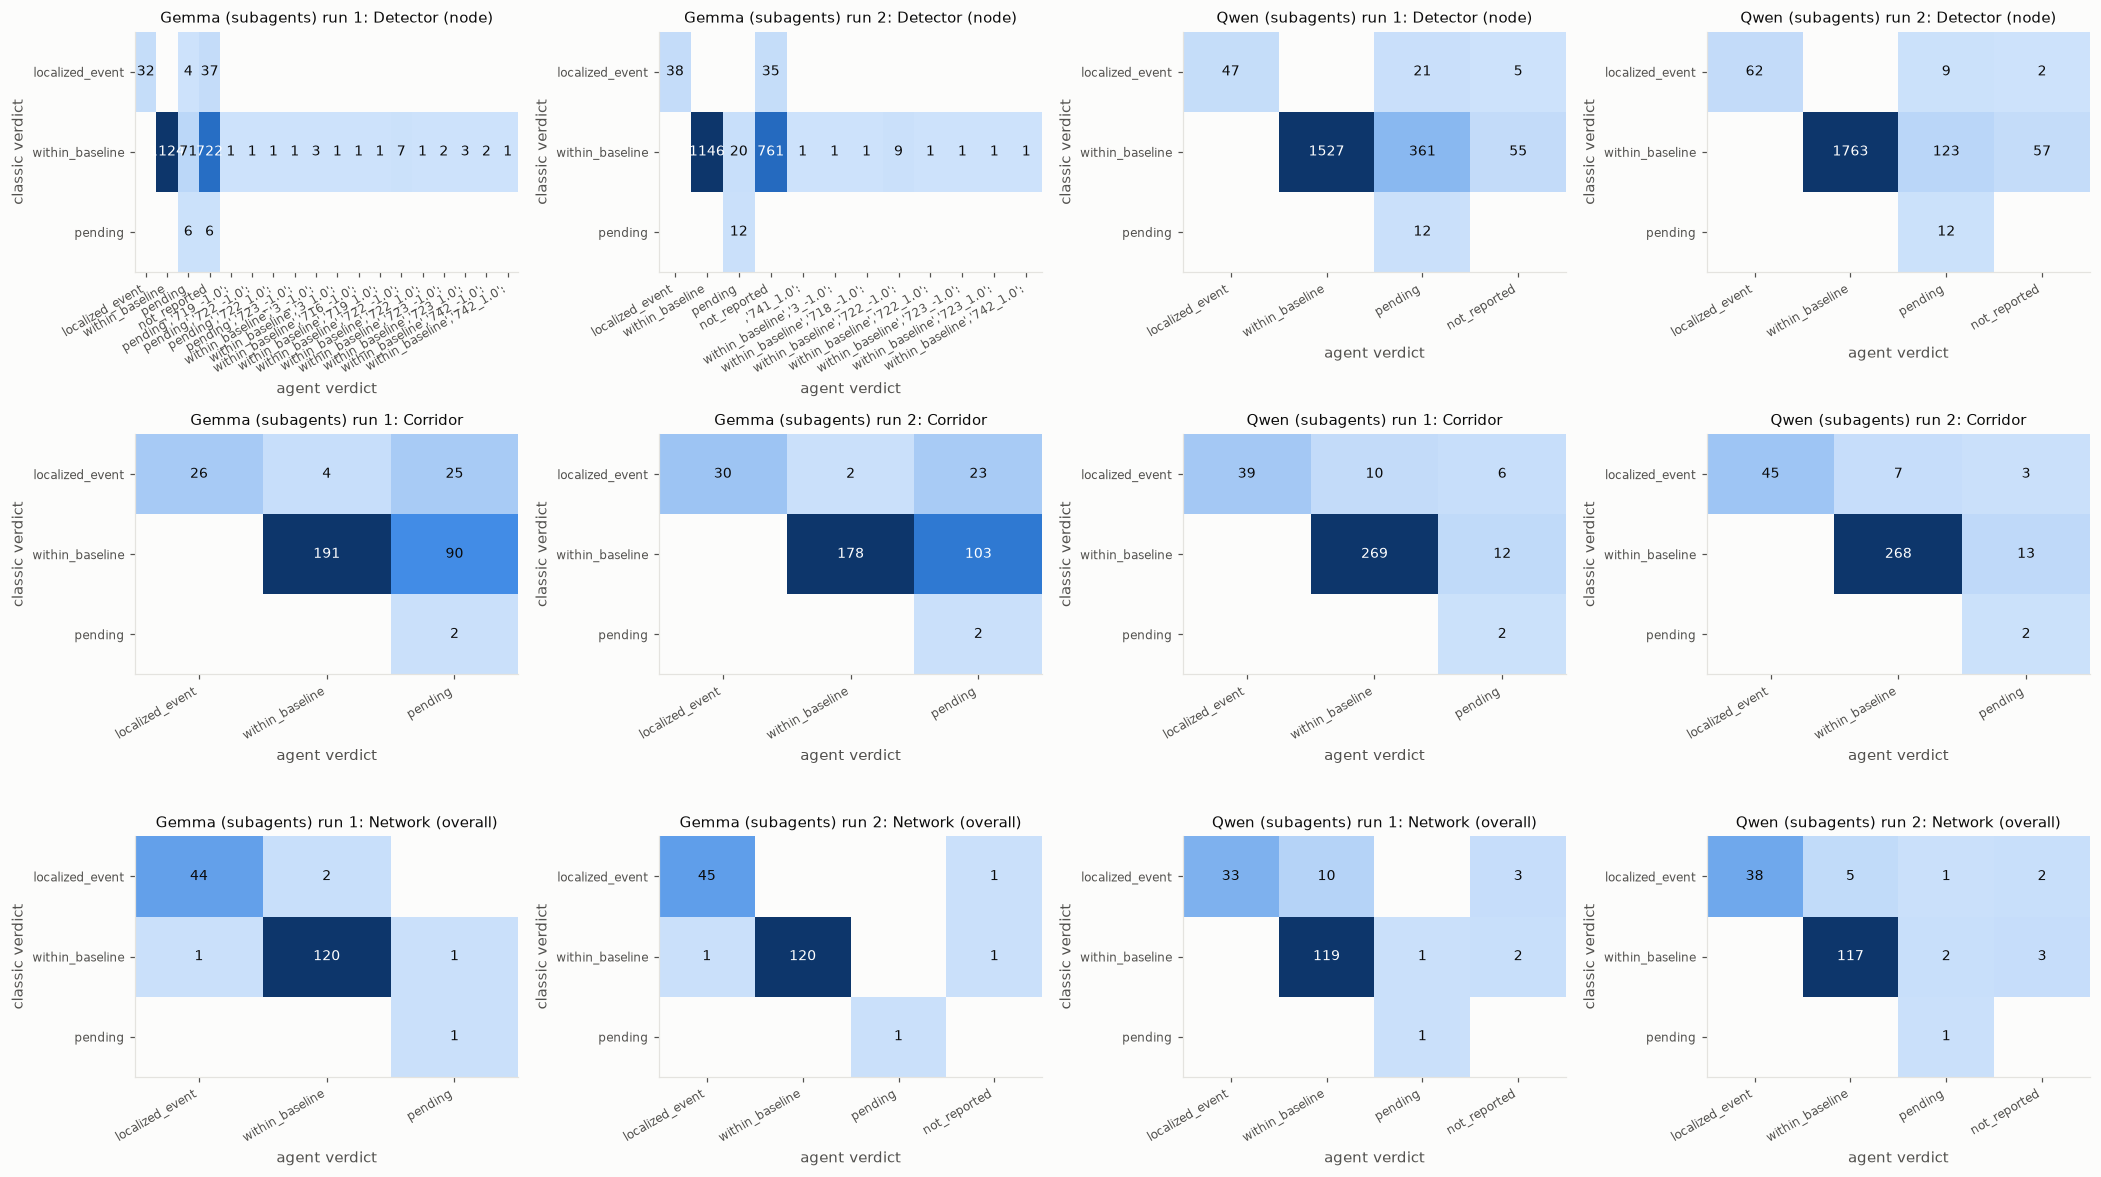

In [6]:
def draw_cm(ax, cm, title):
    cm = cm.loc[cm.sum(axis=1) > 0]                       # classic never produces some labels (e.g. not_reported)
    vals = cm.values.astype(float)
    cmap = SEQ.copy(); cmap.set_bad(SURFACE)               # zero cells stay empty, they are not "a little"
    ax.imshow(np.ma.masked_where(vals == 0, vals), cmap=cmap, vmin=0, vmax=max(vals.max(), 1), aspect="auto")
    ax.set_xticks(range(len(cm.columns))); ax.set_xticklabels(cm.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(cm.index))); ax.set_yticklabels(cm.index, fontsize=8)
    ax.grid(False); ax.set_title(title, fontsize=10)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = int(vals[i, j])
            ax.text(j, i, f"{v}" if v else "", ha="center", va="center", fontsize=9,
                    color="white" if vals[i, j] > 0.5 * max(vals.max(), 1) else INK)
    ax.set_xlabel("agent verdict"); ax.set_ylabel("classic verdict")

names = [n for n, r in R.items() if r["per_node"] is not None]
lv = {n: levels(R[n]) for n in names}
level_names = ["Detector (node)", "Corridor", "Network (overall)"]
fig, axes = plt.subplots(len(level_names), len(names), figsize=(4.8 * len(names), 3.6 * len(level_names)), squeeze=False)
for i, L in enumerate(level_names):
    for j, n in enumerate(names):
        df = lv[n][L]
        if df.empty:
            axes[i][j].axis("off"); continue
        cm, _ = confusion(df)
        cm.to_csv(OUT / f"2_confusion_{L.split()[0].lower()}_{n}.csv")
        draw_cm(axes[i][j], cm, f"{n}: {L}")
plt.tight_layout(); plt.show()

## 3. Failure and disagreement analysis (essential)

Explains *why* the agentic runs differ from the baseline: missing predictions, wrong tool arguments,
incomplete evaluations, classification disagreements and failed sessions.

In [7]:
def failed_sessions(r):
    t = r["timing"].set_index("hour"); l = r["ph_last"].set_index("hour")
    d = pd.DataFrame(index=t.index)
    d["seconds"] = t.seconds
    d["goose_exit"] = t.goose_exit.astype(str)
    d["nonzero_exit"] = d.goose_exit != "0"
    d["no_run_summary"] = ~l.log_run_summary_ok.astype(bool).reindex(d.index).fillna(False)
    d["no_final_ditto"] = ~l.log_final_ditto_ok.astype(bool).reindex(d.index).fillna(False)
    d["missing_predictions"] = l.missing_nodes.fillna("").map(lambda s: len(s.split())).reindex(d.index).fillna(0).astype(int)
    d["incomplete_evaluation"] = (l.eval_coverage_vs_classic.reindex(d.index) < 1).fillna(False)
    d["bad_eval_args"] = (l.check_deviation_bad_args.reindex(d.index).fillna(0) > 0)
    d["bad_payloads"] = (l.payload_bad_calls.reindex(d.index).fillna(0) > 0)
    calls = r["calls"]
    stalled = set(calls[calls.latency_s > STALL_S].hour)
    d["stalled_request"] = d.index.isin(stalled)
    d["tool_errors"] = l.tool_errors.reindex(d.index).fillna(0).astype(int)
    return d

fs = {n: failed_sessions(r) for n, r in R.items() if r["per_hour"] is not None}
summary = {}
for n, d in fs.items():
    n_s = len(d)
    summary[n] = {
        "sessions": n_s,
        "goose exit code != 0": int(d.nonzero_exit.sum()),
        "no run summary logged": int(d.no_run_summary.sum()),
        "no final Ditto record": int(d.no_final_ditto.sum()),
        "sessions with missing predictions": int((d.missing_predictions > 0).sum()),
        "missing prediction node-hours": int(d.missing_predictions.sum()),
        "sessions with incomplete evaluations": int(d.incomplete_evaluation.sum()),
        "sessions with wrong check_deviation arguments": int(d.bad_eval_args.sum()),
        "sessions with wrong baseline_predict payloads": int(d.bad_payloads.sum()),
        f"sessions with a request slower than {STALL_S}s": int(d.stalled_request.sum()),
        "sessions with tool errors": int((d.tool_errors > 0).sum()),
        "sessions with no problem at all": int((~(d.nonzero_exit | d.no_run_summary | d.no_final_ditto | (d.missing_predictions > 0)
                                                  | d.incomplete_evaluation | d.bad_eval_args | d.bad_payloads | d.stalled_request)).sum()),
    }
show(pd.DataFrame(summary), "Session-level failure summary", "3_failure_summary")
for n, d in fs.items():
    d.to_csv(OUT / f"3_sessions_{n}.csv")

**Session-level failure summary**

,Gemma (subagents) run 1,Gemma (subagents) run 2,Qwen (subagents) run 1,Qwen (subagents) run 2
sessions,169,169,169,169
goose exit code != 0,0,0,0,0
no run summary logged,0,2,5,5
no final Ditto record,0,2,5,5
sessions with missing predictions,52,52,73,43
missing prediction node-hours,92,90,274,148
sessions with incomplete evaluations,58,16,88,38
sessions with wrong check_deviation arguments,0,0,8,3
sessions with wrong baseline_predict payloads,96,101,15,9
sessions with a request slower than 300s,12,13,0,0


In [8]:
# which nodes are missed, and what kind of wrong arguments occur
for n, r in R.items():
    if r["per_hour"] is None:
        continue
    miss = Counter(x for s in r["ph_last"].missing_nodes.fillna("") for x in s.split())
    iss = Counter(x for s in r["per_node"].payload_issues.fillna("") for x in s.split())
    c1 = pd.DataFrame(miss.most_common(15), columns=["node", "hours missed"]).set_index("node")
    c2 = pd.DataFrame(iss.most_common(15), columns=["payload issue", "count"]).set_index("payload issue")
    show(c1, f"{n}: most frequently missing predictions (hours missed)", f"3_missing_nodes_{n}")
    show(c2, f"{n}: wrong-payload issue types in baseline_predict", f"3_payload_issues_{n}")

**Gemma (subagents) run 1: most frequently missing predictions (hours missed)**

,hours missed
node,
716_1.0,10
741_-1.0,10
719_-1.0,9
3_1.0,9
722_1.0,9
716_-1.0,8
718_-1.0,8
718_1.0,7
741_1.0,6


**Gemma (subagents) run 1: wrong-payload issue types in baseline_predict**

,count
payload issue,
missing_field:precipitation,116
missing_field:flows_24,31
wrong_timestamp,8
wrong_value:flows_168,3
wrong_value:flows_1,3
wrong_value:flows_24,3
wrong_value:precipitation,2
wrong_value:temperature,2
missing_field:flows_1,1


**Gemma (subagents) run 2: most frequently missing predictions (hours missed)**

...

,count
payload issue,
wrong_value:flows_24,6
wrong_value:flows_168,5
wrong_value:flows_1,4
wrong_value:precipitation,2
wrong_value:temperature,2
invalid_payload,1


**Qwen (subagents) run 2: most frequently missing predictions (hours missed)**

,hours missed
node,
3_1.0,16
741_-1.0,16
718_1.0,14
722_-1.0,14
716_-1.0,14
3_-1.0,13
722_1.0,12
716_1.0,11
741_1.0,10


**Qwen (subagents) run 2: wrong-payload issue types in baseline_predict**

,count
payload issue,
wrong_value:flows_24,4
wrong_value:flows_168,2
wrong_value:flows_1,2
invalid_payload,1
wrong_value:precipitation,1
wrong_value:temperature,1


In [9]:
# classification disagreements, with the most likely cause
def disagreements(r):
    pn = r["per_node"]; l = r["ph_last"].set_index("hour")
    d = pn[pn.verdict_classic.notna() & (pn.verdict_classic != pn.verdict_agent.fillna("not_reported"))].copy()
    d["verdict_agent"] = d.verdict_agent.map(clean)
    bad_eval = l.check_deviation_bad_args.reindex(d.hour).fillna(0).values > 0
    def cause(row, be):
        if row.verdict_agent == "not_reported":
            return "agent reported no verdict (evaluation or summary missing)"
        if be:
            return "session had wrong check_deviation arguments"
        if not bool(row.prev_hour_prediction_matched):
            return "previous-hour prediction differed from classic (different baseline)"
        return "different verdict although inputs matched (rule applied differently)"
    d["likely_cause"] = [cause(row, be) for row, be in zip(d.itertuples(), bad_eval)]
    return d

for n, r in R.items():
    if r["per_node"] is None:
        continue
    d = disagreements(r)
    tot = int(r["per_node"].verdict_classic.notna().sum())
    c = d.likely_cause.value_counts().to_frame("node-hours")
    c["share of disagreements"] = (c["node-hours"] / max(len(d), 1)).round(3)
    show(c, f"{n}: {len(d)} disagreements out of {tot} node-hours", f"3_disagreement_causes_{n}")
    pair = d.groupby(["verdict_classic", "verdict_agent"]).size().rename("node-hours").to_frame()
    show(pair, f"{n}: which verdicts were confused", f"3_disagreement_pairs_{n}")
    cols = ["hour", "node", "verdict_classic", "verdict_agent", "likely_cause", "classic_prediction", "agent_prediction", "actual_flow"]
    d[cols].to_csv(OUT / f"3_disagreements_{n}.csv", index=False)

**Gemma (subagents) run 1: 866 disagreements out of 2028 node-hours**

,node-hours,share of disagreements
likely_cause,,
agent reported no verdict (evaluation or summary missing),765,0.883
previous-hour prediction differed from classic (different baseline),72,0.083
different verdict although inputs matched (rule applied differently),29,0.033


**Gemma (subagents) run 1: which verdicts were confused**

node-hours
verdict_classic verdict_agent                           
localized_event not_reported                          37
                pending                                4
pending         not_reported                           6
within_baseline not_reported                         722
                pending                               71
                pending','719_-1.0':                   1
                pending','722_-1.0':                   1
                pending','722_1.0':                    1
                pending','723_-1.0':                   1
                within_baseline','3_-1.0':             3
                within_baseline','3_1.0':              1
                within_baseline','716_-1.0':           1
                within_baseline','719_1.0':            1
                within_baseline','722_-1.0':           7
                within_baseline','722_1.0':            1
                within_baseline','723_-1.0':           2
                within_baseline','723_1.0':            3
                within_baseline','742_-1.0':           2
                within_baseline','742_1.0':            1

**Gemma (subagents) run 2: 832 disagreements out of 2028 node-hours**

...

node-hours
verdict_classic verdict_agent            
localized_event not_reported            5
                pending                21
within_baseline not_reported           55
                pending               361

**Qwen (subagents) run 2: 191 disagreements out of 2028 node-hours**

,node-hours,share of disagreements
likely_cause,,
different verdict although inputs matched (rule applied differently),108,0.565
agent reported no verdict (evaluation or summary missing),59,0.309
previous-hour prediction differed from classic (different baseline),20,0.105
session had wrong check_deviation arguments,4,0.021


**Qwen (subagents) run 2: which verdicts were confused**

node-hours
verdict_classic verdict_agent            
localized_event not_reported            2
                pending                 9
within_baseline not_reported           57
                pending               123

In [10]:
# tool errors per tool (from the MCP trace) and error strings found in the goose session logs
LOG_PATTERNS = {
    "5-background-task cap refused a delegate": "Maximum 5 background",
    "rate limit error reached the agent": "Rate limit exceeded",
    "delegate source not found": "not found. Use load()",
    "missing required parameters": "Missing required parameters",
    "agent hit its action limit": "maximum number of actions",
}

def trace_errors(r):
    t = r["trace"]
    if t.empty:
        return None
    t = t.assign(is_call=t.phase.eq("CALL"), is_err=t.phase.eq("ERROR"))
    g = t.groupby("tool")
    out = pd.DataFrame({"calls": g.is_call.sum(), "errors": g.is_err.sum()})
    out["answered"] = t[~t.is_call].groupby("tool").size().reindex(out.index).fillna(0).astype(int)
    out["unanswered"] = (out.calls - out.answered).clip(lower=0)
    out["error_rate"] = (out.errors / out.calls.replace(0, np.nan)).round(4)
    return out.sort_values("errors", ascending=False)

def log_errors(r):
    d = r["path"] / "logs"
    if not d.is_dir():
        return None
    rows = {}
    for p in d.glob("*.log"):
        text = p.read_text(errors="ignore")
        rows[p.stem] = {k: text.count(v) for k, v in LOG_PATTERNS.items()}
    return pd.DataFrame(rows).T

for n, r in R.items():
    te = trace_errors(r)
    if te is not None:
        show(te, f"{n}: MCP tool calls and errors (trace.jsonl)", f"3_tool_errors_{n}")
        err_msgs = r["trace"][r["trace"].phase.eq("ERROR")].extra.astype(str).str.slice(0, 90).value_counts().head(10)
        if len(err_msgs):
            show(err_msgs.to_frame("count"), f"{n}: most common error messages", f"3_error_messages_{n}")
    le = log_errors(r)
    if le is not None:
        tot = pd.DataFrame({"occurrences": le.sum(), "sessions affected": (le > 0).sum()})
        show(tot, f"{n}: error strings in the goose session logs ({len(le)} logs)", f"3_log_errors_{n}")
    ph = r["per_hour"]
    if ph is not None and "log_delegate_calls" in ph:
        extra = {"delegate calls": int(ph.log_delegate_calls.sum()),
                 "sessions where the coordinator called pipeline tools itself": int((ph.log_coordinator_direct_tool_calls > 0).sum()),
                 "subagent `load` instead of tools": int(ph.log_subagent_load_misuse.sum())}
        show(pd.Series(extra).to_frame("value"), f"{n}: delegation behaviour (from compare.py)", f"3_delegation_{n}")

**Gemma (subagents) run 1: MCP tool calls and errors (trace.jsonl)**

,calls,errors,answered,unanswered,error_rate
tool,,,,,
baseline_predict,2101,151,2101,0,0.0719
get_pending_prediction,2020,2,2020,0,0.0010
log_final_ditto,170,1,170,0,0.0059
build_summary_table,257,0,257,0,0.0000
get_actual_flow,1918,0,1918,0,0.0000
check_deviation,1907,0,1907,0,0.0000
get_corridor_status,338,0,338,0,0.0000
get_current_timestamp,169,0,169,0,0.0000
get_flows,1994,0,1994,0,0.0000


**Gemma (subagents) run 1: most common error messages**

,count
extra,
Incomplete flows_payload for 719_-1.0: missing fields ['precipitation']. Pass the complete,15
Incomplete flows_payload for 3_1.0: missing fields ['precipitation']. Pass the complete re,13
Incomplete flows_payload for 716_1.0: missing fields ['precipitation']. Pass the complete,13
Incomplete flows_payload for 716_-1.0: missing fields ['precipitation']. Pass the complete,12
Incomplete flows_payload for 741_1.0: missing fields ['precipitation']. Pass the complete,11
Incomplete flows_payload for 741_-1.0: missing fields ['precipitation']. Pass the complete,11
Incomplete flows_payload for 719_1.0: missing fields ['precipitation']. Pass the complete,8
Incomplete flows_payload for 722_-1.0: missing fields ['precipitation']. Pass the complete,7
Incomplete flows_payload for 718_1.0: missing fields ['precipitation']. Pass the complete,7


**Gemma (subagents) run 1: error strings in the goose session logs (169 logs)**

...

,count
extra,
Prediction computed but could not be persisted to historic Ditto:,2
timed out,2
Prediction lookup failed:,1
month must be in 1..12: 2024-00-26T02:00:00,1
flows_payload is not valid JSON: Expecting value: line 1 column 1 (char 0),1
"Prediction failed for 741_1.0: NaN features: ['Avg_Temperature', 'Avg_Precipitation']",1
Could not fetch actual flow for 722_1.0 at 2024-09-29T22:00:00:,1


**Qwen (subagents) run 2: error strings in the goose session logs (169 logs)**

,occurrences,sessions affected
5-background-task cap refused a delegate,20,2
rate limit error reached the agent,7,1
delegate source not found,1,1
missing required parameters,25,2
agent hit its action limit,7,4


**Qwen (subagents) run 2: delegation behaviour (from compare.py)**

,value
delegate calls,4150
sessions where the coordinator called pipeline tools itself,2
subagent `load` instead of tools,712


## 4. Execution time (essential)

Wall time per hourly session from `timing.csv`, against the classic pipeline's own run time
(`classic_total_s` in `per_hour.csv`). *Typical* excludes sessions that contain one stalled LLM request.

In [11]:
def dist(s):
    s = num(s).dropna()
    if s.empty:
        return {}
    return {"n": int(len(s)), "mean": s.mean(), "std": s.std(), "median": s.median(),
            "p90": s.quantile(.90), "p95": s.quantile(.95), "p99": s.quantile(.99), "max": s.max(), "total_hours": s.sum() / 3600}

rows = {}
for n, r in R.items():
    t = r["timing"]; calls = r["calls"]
    stalled = set(calls[calls.latency_s > STALL_S].hour)
    rows[f"{n} (all sessions)"] = dist(t.seconds)
    rows[f"{n} (typical, no stalled request)"] = dist(t[~t.hour.isin(stalled)].seconds)
classic_s = None
for r in R.values():
    if r.get("ph_last") is not None and r["ph_last"].classic_total_s.notna().any():
        classic_s = num(r["ph_last"].classic_total_s); break
if classic_s is not None:
    rows["Classic (deterministic)"] = dist(classic_s)
tt = pd.DataFrame(rows).T.round(1)
show(tt, "Seconds per hourly session", "4_execution_time")

if classic_s is not None:
    ratio = {}
    for n, r in R.items():
        a = num(r["timing"].seconds)
        ratio[n] = {"mean x classic": round(a.mean() / classic_s.mean(), 1), "median x classic": round(a.median() / classic_s.median(), 1)}
    show(pd.DataFrame(ratio).T, "Agent time as a multiple of classic", "4_time_ratio")

feas = {}
for n, r in R.items():
    s = num(r["timing"].seconds)
    feas[n] = {"sessions": len(s), f"finished within {FEASIBLE_S // 60} min": share(int((s <= FEASIBLE_S).sum()), len(s)),
               "finished within 10 min": share(int((s <= 600).sum()), len(s)),
               "slower than the hourly slot": int((s > FEASIBLE_S).sum()), "slowest (min)": round(s.max() / 60, 1),
               "hourly operation feasible (max < slot)": bool(s.max() < FEASIBLE_S)}
show(pd.DataFrame(feas).T, "Feasibility of hourly operation", "4_feasibility")

**Seconds per hourly session**

,n,mean,std,median,p90,p95,p99,max,total_hours
Gemma (subagents) run 1 (all sessions),169.0,363.4,288.0,281.0,370.2,1255.0,1505.2,1815.0,17.1
"Gemma (subagents) run 1 (typical, no stalled request)",157.0,286.1,40.5,279.0,322.6,352.6,453.4,498.0,12.5
Gemma (subagents) run 2 (all sessions),169.0,370.5,312.4,290.0,361.2,1158.2,1705.2,2508.0,17.4
"Gemma (subagents) run 2 (typical, no stalled request)",156.0,289.1,33.1,286.5,332.5,346.0,372.8,406.0,12.5
Qwen (subagents) run 1 (all sessions),169.0,280.4,21.2,281.0,300.0,308.6,334.4,354.0,13.2
"Qwen (subagents) run 1 (typical, no stalled request)",169.0,280.4,21.2,281.0,300.0,308.6,334.4,354.0,13.2
Qwen (subagents) run 2 (all sessions),169.0,341.5,140.7,292.0,443.8,572.0,996.4,1315.0,16.0
"Qwen (subagents) run 2 (typical, no stalled request)",169.0,341.5,140.7,292.0,443.8,572.0,996.4,1315.0,16.0
Classic (deterministic),169.0,17.6,1.5,17.5,19.3,21.0,22.3,24.2,0.8


**Agent time as a multiple of classic**

,mean x classic,median x classic
Gemma (subagents) run 1,20.6,16.0
Gemma (subagents) run 2,21.0,16.6
Qwen (subagents) run 1,15.9,16.0
Qwen (subagents) run 2,19.3,16.7


**Feasibility of hourly operation**

,sessions,finished within 60 min,finished within 10 min,slower than the hourly slot,slowest (min),hourly operation feasible (max < slot)
Gemma (subagents) run 1,169,1.0,0.929,0,30.2,True
Gemma (subagents) run 2,169,1.0,0.9231,0,41.8,True
Qwen (subagents) run 1,169,1.0,1.0,0,5.9,True
Qwen (subagents) run 2,169,1.0,0.9527,0,21.9,True


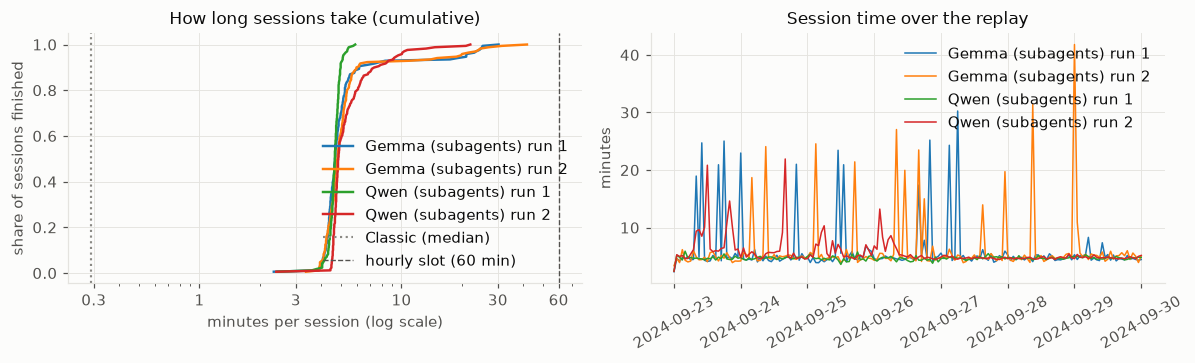

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for n, r in R.items():
    s = np.sort(num(r["timing"].seconds).dropna().values)
    axes[0].plot(s / 60, np.arange(1, len(s) + 1) / len(s), color=COLORS.get(n), label=n)
    t = r["timing"].copy(); t["h"] = pd.to_datetime(t.hour)
    axes[1].plot(t.h, num(t.seconds) / 60, color=COLORS.get(n), lw=1.0, label=n)
if classic_s is not None:
    axes[0].axvline(classic_s.median() / 60, color=COLORS["Classic"], ls=":", lw=1.4, label="Classic (median)")
axes[0].axvline(FEASIBLE_S / 60, color=INK2, ls="--", lw=0.9, label=f"hourly slot ({FEASIBLE_S // 60} min)")
axes[0].set_xscale("log")                                  # classic is ~10x faster, a linear axis would squash everything
axes[0].set_xticks([0.3, 1, 3, 10, 30, 60]); axes[0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
axes[0].set_xlabel("minutes per session (log scale)"); axes[0].set_ylabel("share of sessions finished")
axes[0].set_title("How long sessions take (cumulative)"); axes[0].legend(loc="lower right")
axes[1].set_ylabel("minutes"); axes[1].set_title("Session time over the replay"); axes[1].legend(loc="upper right")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 5. LLM resource consumption (important)

From `llm_calls.jsonl` (one line per request, usage as reported by the server). Every request is one agent turn,
including requests made by subagents. goose counts `GOOSE_MAX_TURNS` per agent, and the log does not say which agent
sent a request, so requests per session are an upper bound on any single agent's turns. `max_messages / 2` is shown as
an approximation of the longest conversation (usually the coordinator).

In [13]:
def per_session(r):
    c = r["calls"].copy()
    c["is_retried"] = c.retries.fillna(0) > 0
    c["is_trunc"] = c.finish_reason.eq("length")
    c["is_runaway"] = c.completion_tokens > RUNAWAY_TOKENS
    c["runaway_tokens"] = c.completion_tokens.where(c.is_runaway, 0)
    c["over_limit"] = c.prompt_tokens > CONTEXT_LIMIT
    c["over_80"] = c.prompt_tokens > 0.8 * CONTEXT_LIMIT
    c["failed"] = ~c.status.between(200, 299) | c.error.notna()
    g = c.groupby("hour")
    s = pd.DataFrame({
        "requests": g.size(), "input_tokens": g.prompt_tokens.sum(min_count=1), "output_tokens": g.completion_tokens.sum(min_count=1),
        "max_prompt_tokens": g.prompt_tokens.max(), "max_messages": g.n_messages.max(),
        "retried": g.is_retried.sum(), "truncated": g.is_trunc.sum(), "runaway_tokens": g.runaway_tokens.sum(),
        "summarize_flagged": g.summarize_hint.sum(), "over_limit": g.over_limit.sum(), "over_80": g.over_80.sum(),
        "failed": g.failed.sum(), "mean_latency_s": g.latency_s.mean(),
    })
    s["output_excl_runaway"] = s.output_tokens - s.runaway_tokens
    return s.reindex(r["timing"].hour)

PS = {n: per_session(r) for n, r in R.items()}
for n, s in PS.items():
    s.to_csv(OUT / f"5_per_session_{n}.csv")

def resource(n, r):
    s, c = PS[n], r["calls"]
    d = {}
    for col, label in (("requests", "LLM requests per session (turns incl. subagents)"),
                       ("input_tokens", "input tokens per session"), ("output_tokens", "output tokens per session"),
                       ("output_excl_runaway", f"output tokens per session excl. responses > {RUNAWAY_TOKENS}")):
        for k, v in dist(s[col]).items():
            if k in ("mean", "median", "p90", "max"):
                d[(label, k)] = round(v, 1)
    d[("tokens per request", "mean input")] = round(c.prompt_tokens.mean(), 1)
    d[("tokens per request", "median output")] = round(c.completion_tokens.median(), 1)
    d[("tokens per request", "p99 output")] = round(c.completion_tokens.quantile(.99), 1)
    d[("totals", "input tokens")] = int(c.prompt_tokens.sum()); d[("totals", "output tokens")] = int(c.completion_tokens.sum())
    d[("totals", "LLM requests")] = len(c)
    d[("totals", "usage reported by the server")] = round((c.usage_source == "server").mean(), 4)
    d[("totals", "prompt tokens served from cache (if reported)")] = (
        round(c.cached_tokens.sum() / c.prompt_tokens.sum(), 4) if c.cached_tokens.notna().any() else "not reported")
    d[(f"context (limit {CONTEXT_LIMIT})", "largest prompt (tokens)")] = int(c.prompt_tokens.max())
    d[(f"context (limit {CONTEXT_LIMIT})", "largest prompt as % of limit")] = round(100 * c.prompt_tokens.max() / CONTEXT_LIMIT, 1)
    d[(f"context (limit {CONTEXT_LIMIT})", "requests above 80% of limit")] = int((c.prompt_tokens > .8 * CONTEXT_LIMIT).sum())
    d[(f"context (limit {CONTEXT_LIMIT})", "requests above the limit")] = int((c.prompt_tokens > CONTEXT_LIMIT).sum())
    d[(f"context (limit {CONTEXT_LIMIT})", "sessions with a request above the limit")] = int((s.over_limit > 0).sum())
    d[("summarisation", "requests flagged as summarise (heuristic: no tools + 'summar')")] = int(c.summarize_hint.sum())
    d[("summarisation", "sessions with a flagged request")] = int((s.summarize_flagged > 0).sum())
    d[(f"turns (max {MAX_TURNS})", "sessions with requests >= max turns")] = int((s.requests >= MAX_TURNS).sum())
    d[(f"turns (max {MAX_TURNS})", "longest conversation, approx. turns (max_messages / 2)")] = round(s.max_messages.max() / 2, 1)
    d[("errors and stalls", "LLM requests failed or errored")] = int(s.failed.sum())
    d[("errors and stalls", "requests retried after 429/503")] = int(s.retried.sum())
    d[("errors and stalls", "responses cut off (finish_reason=length)")] = int(s.truncated.sum())
    d[("errors and stalls", "output tokens in runaway responses")] = int(s.runaway_tokens.sum())
    d[("errors and stalls", "share of all output tokens")] = round(s.runaway_tokens.sum() / max(c.completion_tokens.sum(), 1), 4)
    d[("errors and stalls", f"requests slower than {STALL_S}s")] = int((c.latency_s > STALL_S).sum())
    d[("errors and stalls", "mean request latency (s)")] = round(c.latency_s.mean(), 2)
    if r["per_hour"] is not None:
        te = r["ph_last"].tool_errors
        d[("errors and stalls", "MCP tool errors (total)")] = int(te.sum())
        d[("errors and stalls", "sessions with an MCP tool error")] = int((te > 0).sum())
    return d

res = pd.DataFrame({n: resource(n, r) for n, r in R.items()})
res.index.names = ["Area", "Metric"]
show(res, "LLM resource consumption", "5_resources")

**LLM resource consumption**

Gemma (subagents) run 1  Gemma (subagents) run 2  Qwen (subagents) run 1  \
Area                                              Metric                                                                                                                                     
LLM requests per session (turns incl. subagents)  mean                                                                       1.253000e+02             1.241000e+02            9.160000e+01   
                                                  median                                                                     1.230000e+02             1.230000e+02            9.600000e+01   
                                                  p90                                                                        1.480000e+02             1.492000e+02            1.002000e+02   
                                                  max                                                                        2.410000e+02             1.600000e+02            1.060000e+02   
input tokens per session                          mean                                                                       1.012977e+06             1.021277e+06            4.703617e+05   
                                                  median                                                                     1.018923e+06             1.000812e+06            4.993830e+05   
                                                  p90                                                                        1.349296e+06             1.444805e+06            5.315132e+05   
                                                  max                                                                        1.942808e+06             1.676950e+06            6.339340e+05   
output tokens per session                         mean                                                                       5.138320e+04             5.116300e+04            2.558830e+04   
                                                  median                                                                     4.305700e+04             4.457400e+04            2.464800e+04   
                                                  p90                                                                        4.989140e+04             5.082320e+04            3.037640e+04   
                                                  max                                                                        1.834420e+05             2.058140e+05            4.233800e+04   
output tokens per session excl. responses > 20000 mean                                                                       4.391290e+04             4.383600e+04            2.558830e+04   
                                                  median                                                                     4.289300e+04             4.413300e+04            2.464800e+04   
                                                  p90                                                                        4.759080e+04             4.852300e+04            3.037640e+04   
                                                  max                                                                        9.044700e+04             5.724100e+04            4.233800e+04   
tokens per request                                mean input                                                                 8.098800e+03             8.232200e+03            5.306800e+03   
                                                  median output                                                              2.510000e+02             2.500000e+02            1.390000e+02   
                                                  p99 output                                                                 3.141000e+03             3.224800e+03            3.837200e+03   
totals                                            input tokens                                                              

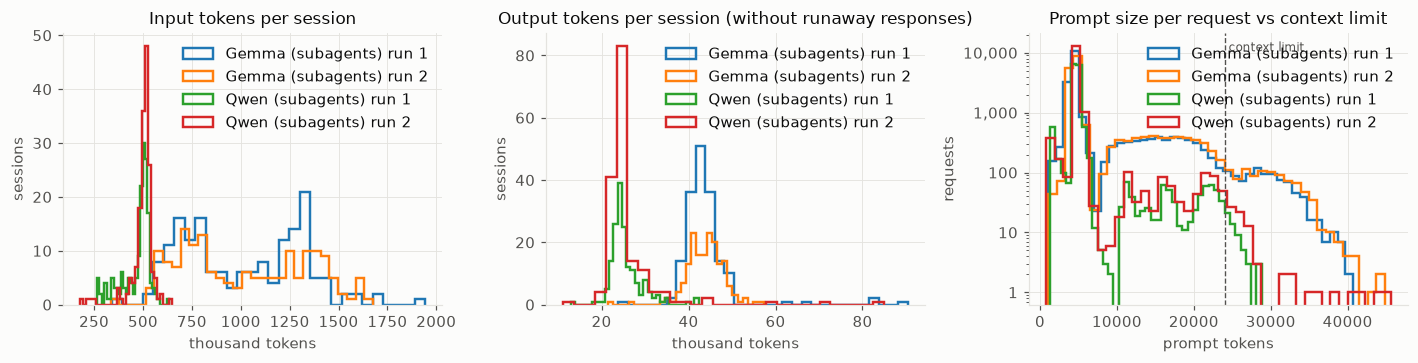

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
def hist(ax, getter, bins, title, xlabel, logy=False):
    for n in R:
        x = getter(n).dropna()
        ax.hist(x, bins=bins, histtype="step", lw=1.6, color=COLORS.get(n), label=n)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("sessions" if not logy else "requests")
    if logy:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.legend()
hist(axes[0], lambda n: PS[n].input_tokens / 1e3, 30, "Input tokens per session", "thousand tokens")
hist(axes[1], lambda n: PS[n].output_excl_runaway / 1e3, 30, "Output tokens per session (without runaway responses)", "thousand tokens")
hist(axes[2], lambda n: R[n]["calls"].prompt_tokens, 40, "Prompt size per request vs context limit", "prompt tokens", logy=True)
axes[2].axvline(CONTEXT_LIMIT, color=INK2, ls="--", lw=0.9)
axes[2].text(CONTEXT_LIMIT, 0.97, " context limit", transform=axes[2].get_xaxis_transform(), color=INK2, fontsize=8, va="top")
plt.tight_layout(); plt.show()

## 6. Five-year cost comparison (important)

Fill in the two parameter cells, then run the rest. The token numbers come from section 5, so they are measured, not assumed.

* **Local:** hardware capex amortised over the 5 years and divided by the number of runs (electricity ignored, as agreed).
* **API:** price per million tokens x measured tokens per run x number of runs.
* **Break-even:** the number of runs at which the API bill equals the hardware cost.
* Three token scenarios: *observed* (runaway responses included), *runaways removed* (the realistic target once outputs are capped)
  and *capped* (every response limited to `OUTPUT_CAP` tokens).

In [15]:
RUNS_PER_HOUR = 1
YEARS = 5
N_RUNS = 24 * 365 * YEARS * RUNS_PER_HOUR          # 43,800 hourly runs

HARDWARE_COST = 6000      # hardware cost of local
CURRENCY = "USD"
OUTPUT_CAP = 4096         # tokens, used by the 'capped' scenario

# price per million tokens; providers / models
# cached_in is optional (price of cached input tokens); None = no cache discount applied.

# https://openrouter.ai/compare/qwen/qwen3.8-27b/google/gemma-4-26b-a4b-it
API = {
    # "Provider model": {"in": 0.30, "out": 2.50, "cached_in": 0.03},
    "Qwen": {
        "in": 0.020,
        "out": 0.500,
        "cached_in": 0.009,
    },
    "Gemma": {
        "in": 0.042,
        "out": 0.220,
        "cached_in": 0.021,
    },
}

In [16]:
def token_scenarios(r):
    c = r["calls"]; sessions = r["timing"].hour.nunique()
    obs_in, obs_out = c.prompt_tokens.sum() / sessions, c.completion_tokens.sum() / sessions
    run = c[~(c.completion_tokens > RUNAWAY_TOKENS)]
    cap = c.completion_tokens.clip(upper=OUTPUT_CAP)
    cached = (c.cached_tokens.sum() / c.prompt_tokens.sum()) if c.cached_tokens.notna().any() else 0.0
    return {
        "observed": (obs_in, obs_out),
        "runaways removed": (run.prompt_tokens.sum() / sessions, run.completion_tokens.sum() / sessions),
        f"output capped at {OUTPUT_CAP}": (obs_in, cap.sum() / sessions),
    }, cached

rows = []
for n, r in R.items():
    sc, cached = token_scenarios(r)
    for name, (i, o) in sc.items():
        rows.append({"model": n, "scenario": name, "input tokens / run": round(i), "output tokens / run": round(o),
                     "input tokens, 5 years (millions)": round(i * N_RUNS / 1e6, 1),
                     "output tokens, 5 years (millions)": round(o * N_RUNS / 1e6, 1), "cached share of prompt": round(cached, 3)})
tok = pd.DataFrame(rows).set_index(["model", "scenario"])
show(tok, f"Measured tokens per run and over {N_RUNS:,} runs", "6_tokens")

**Measured tokens per run and over 43,800 runs**

input tokens / run  output tokens / run  input tokens, 5 years (millions)  output tokens, 5 years (millions)  cached share of prompt
model                   scenario                                                                                                                                                   
Gemma (subagents) run 1 observed                          1012977                51383                           44368.4                             2250.6                   0.863
                        runaways removed                  1011232                43913                           44292.0                             1923.4                   0.863
                        output capped at 4096             1012977                43557                           44368.4                             1907.8                   0.863
Gemma (subagents) run 2 observed                          1021277                51163                           44731.9                             2240.9                   0.865
                        runaways removed                  1019764                43836                           44665.7                             1920.0                   0.865
                        output capped at 4096             1021277                43396                           44731.9                             1900.7                   0.865
Qwen (subagents) run 1  observed                           470362                25588                           20601.8                             1120.8                   0.219
                        runaways removed                   470362                25588                           20601.8                             1120.8                   0.219
                        output capped at 4096              470362                25017                           20601.8                             1095.7                   0.219
Qwen (subagents) run 2  observed                           499074                26054                           21859.4                             1141.2                   0.206
                        runaways removed                   499074                26054                           21859.4                             1141.2                   0.206
                        output capped at 4096              499074                25425                           21859.4                             1113.6                   0.206

**Five-year cost: local hardware vs API**

API cost per run (USD)  API cost, 5 years (USD)  local cost per run (USD)  local cost, 5 years (USD)  break-even (runs)  \
model                   scenario              provider                                                                                                                            
Gemma (subagents) run 1 observed              Qwen                      0.0363                     1591                     0.137                       6000             165138   
                                              Gemma                     0.0355                     1554                     0.137                       6000             169071   
                        runaways removed      Qwen                      0.0326                     1427                     0.137                       6000             184163   
                                              Gemma                     0.0338                     1481                     0.137                       6000             177499   
                        output capped at 4096 Qwen                      0.0324                     1420                     0.137                       6000             185070   
                                              Gemma                     0.0338                     1479                     0.137                       6000             177692   
Gemma (subagents) run 2 observed              Qwen                      0.0363                     1590                     0.137                       6000             165320   
                                              Gemma                     0.0356                     1560                     0.137                       6000             168515   
                        runaways removed      Qwen                      0.0326                     1428                     0.137                       6000             183970   
                                              Gemma                     0.0340                     1487                     0.137                       6000             176694   
                        output capped at 4096 Qwen                      0.0324                     1420                     0.137                       6000             185130   
                                              Gemma                     0.0339                     1485                     0.137                       6000             177011   
Qwen (subagents) run 1  observed              Qwen                      0.0211                      923                     0.137                       6000             284809   
                                              Gemma                     0.0232                     1017                     0.137                       6000             258415   
                        runaways removed      Qwen                      0.0211                      923                     0.137                       6000             284809   
                                              Gemma                     0.0232                     1017                     0.137                       6000             258415   
                        output capped at 4096 Qwen                      0.0208                      910                     0.137                       6000             288728   
                                              Gemma                     0.0231                     1011                     0.137                       6000             259823   
Qwen (subagents) run 2  observed              Qwen                      0.0219                      958                     0.137                       6000             274257   
                                              Gemma                     0.0245                     1075                     0.137                       6000             244564   
                        runaways removed      Qwen                      0.0219                      958               

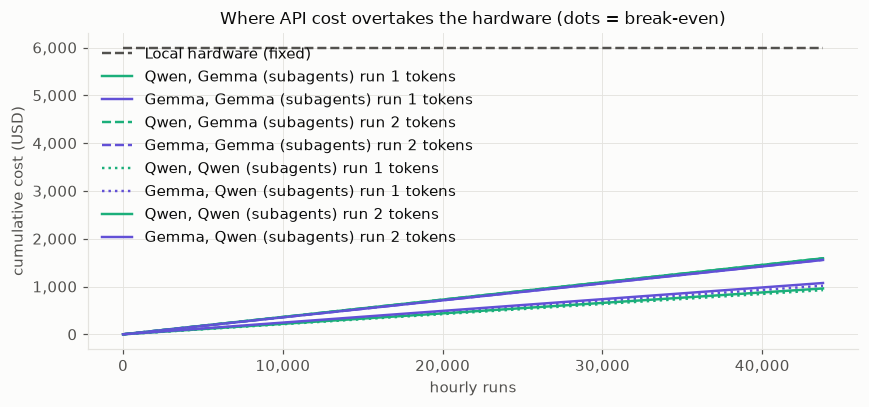

In [17]:
if HARDWARE_COST is None or not API:
    display(Markdown("**Set `HARDWARE_COST` and at least one entry in `API` in the cell above, then re-run this cell.**"))
else:
    rows = []
    local_per_run = HARDWARE_COST / N_RUNS
    for n, r in R.items():
        sc, cached = token_scenarios(r)
        for scen, (i, o) in sc.items():
            for prov, p in API.items():
                cin = p["in"]
                if p.get("cached_in") is not None and cached > 0:
                    cin = cached * p["cached_in"] + (1 - cached) * p["in"]
                per_run = (i * cin + o * p["out"]) / 1e6
                rows.append({"model": n, "scenario": scen, "provider": prov,
                             f"API cost per run ({CURRENCY})": round(per_run, 4),
                             f"API cost, {YEARS} years ({CURRENCY})": round(per_run * N_RUNS),
                             f"local cost per run ({CURRENCY})": round(local_per_run, 4),
                             f"local cost, {YEARS} years ({CURRENCY})": round(HARDWARE_COST),
                             "break-even (runs)": round(HARDWARE_COST / per_run) if per_run else None,
                             "break-even (years at 1 run/hour)": round(HARDWARE_COST / per_run / (24 * 365 * RUNS_PER_HOUR), 2) if per_run else None,
                             "cheaper over 5 years": "local" if HARDWARE_COST < per_run * N_RUNS else "API"})
    cost = pd.DataFrame(rows).set_index(["model", "scenario", "provider"])
    show(cost, "Five-year cost: local hardware vs API", "6_cost")

    fig, ax = plt.subplots(figsize=(8, 3.8))
    x = np.linspace(0, N_RUNS, 100)
    ax.plot(x, np.full_like(x, HARDWARE_COST), color=INK2, ls="--", label="Local hardware (fixed)")
    # colour = API provider (fixed order), line style = which model's measured tokens are priced; observed scenario
    PROV_COLORS = ["#1baf7a", "#6250d6", "#e87ba4", "#008300"]
    STYLES = ["-", "--", ":"]
    models = list(R)
    for (n, scen, prov), row in cost.iterrows():
        if scen != "observed":
            continue
        per_run = row[f"API cost per run ({CURRENCY})"]
        color = PROV_COLORS[list(API).index(prov) % len(PROV_COLORS)]
        ax.plot(x, x * per_run, color=color, ls=STYLES[models.index(n) % 3], label=f"{prov}, {n} tokens")
        be = HARDWARE_COST / per_run
        if be <= N_RUNS:
            ax.plot([be], [HARDWARE_COST], "o", ms=6, color=color, mec=SURFACE, mew=1.5, zorder=5)
    ax.set_xlabel("hourly runs"); ax.set_ylabel(f"cumulative cost ({CURRENCY})")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.set_title("Where API cost overtakes the hardware (dots = break-even)")
    ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

## Export

Everything above was saved as CSV in `analysis_out/`. This cell lists what was written.

In [18]:
for p in sorted(OUT.glob("*.csv")):
    print(f"{p.stat().st_size:>9,d}  {p}")

    2,335  analysis_out/1_fidelity.csv
    2,244  analysis_out/2_agreement.csv
      111  analysis_out/2_confusion_corridor_Gemma (subagents) run 1.csv
      112  analysis_out/2_confusion_corridor_Gemma (subagents) run 2.csv
      111  analysis_out/2_confusion_corridor_Gemma.csv
      111  analysis_out/2_confusion_corridor_Qwen (subagents) run 1.csv
      110  analysis_out/2_confusion_corridor_Qwen (subagents) run 2.csv
      111  analysis_out/2_confusion_corridor_Qwen.csv
    1,554  analysis_out/2_confusion_detector_Gemma (subagents) run 1.csv
      863  analysis_out/2_confusion_detector_Gemma (subagents) run 2.csv
    1,554  analysis_out/2_confusion_detector_Gemma.csv
      155  analysis_out/2_confusion_detector_Qwen (subagents) run 1.csv
      154  analysis_out/2_confusion_detector_Qwen (subagents) run 2.csv
      155  analysis_out/2_confusion_detector_Qwen.csv
      109  analysis_out/2_confusion_network_Gemma (subagents) run 1.csv
      149  analysis_out/2_confusion_network_Gemma (